<a href="https://colab.research.google.com/github/AmitabhTS/AML-LAB-EXPERIMENTS/blob/main/AMLEXP9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

car_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/AML/car_price_cleaned.csv")
target_car = "price"       # Change according to the actual dataset

# Feature engineering
current_year = pd.Timestamp.now().year

if "year" in car_df.columns:
    car_df["vehicle_age"] = current_year - car_df["year"]

if "km_driven" in car_df.columns and "vehicle_age" in car_df.columns:
    car_df["km_per_year"] = (
        car_df["km_driven"] / (car_df["vehicle_age"] + 1)
    )

# Remove target and rows with missing target
car_df = car_df.dropna(subset=[target_car])

# Clean and convert the target column to numeric
car_df[target_car] = car_df[target_car].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False).astype(float)

X = car_df.drop(target_car, axis=1)
y = car_df[target_car]

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numerical", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        random_state=42,
        max_depth=12
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)
car_predictions = {}

for name, regressor in models.items():
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", regressor)
    ])
    model.fit(X_train, y_train)
    car_predictions[name] = model.predict(X_test)
    print(name, "training completed")


Linear Regression training completed
Decision Tree training completed
Random Forest training completed
Gradient Boosting training completed


,Model,MAE,MSE,RMSE,R2 Score
1,Decision Tree,25346.333423,1.872991e+10,136857.259320,0.083645
2,Random Forest,19860.484258,1.895813e+10,137688.531829,0.072479
3,Gradient Boosting,24303.024579,1.909076e+10,138169.304322,0.065990
0,Linear Regression,44018.134388,2.042033e+10,142899.708695,0.000942


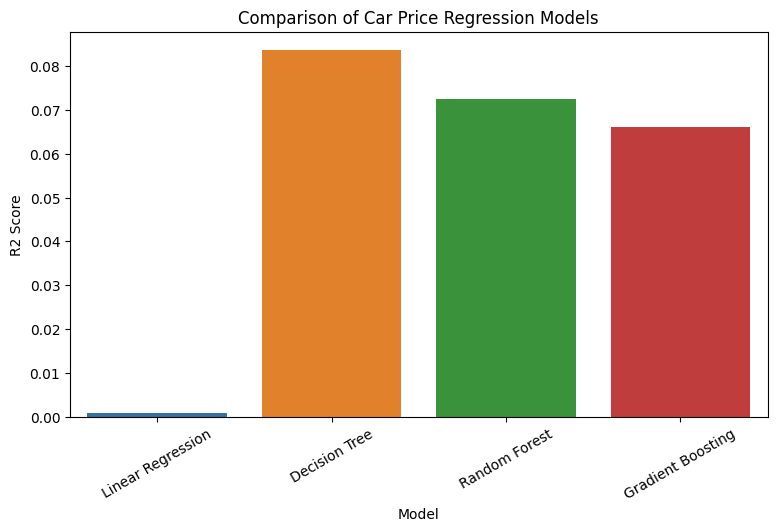

Best regression model: Decision Tree


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

car_results = []

for name, prediction in car_predictions.items():
    mae = mean_absolute_error(y_test, prediction)
    mse = mean_squared_error(y_test, prediction)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, prediction)

    car_results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

car_results_df = pd.DataFrame(car_results)
display(car_results_df.sort_values("R2 Score", ascending=False))

plt.figure(figsize=(9, 5))
sns.barplot(
    data=car_results_df,
    x="Model",
    y="R2 Score",
    hue="Model",
    legend=False
)
plt.xticks(rotation=30)
plt.title("Comparison of Car Price Regression Models")
plt.show()

best_car_model = car_results_df.loc[
    car_results_df["R2 Score"].idxmax(), "Model"
]

print("Best regression model:", best_car_model)


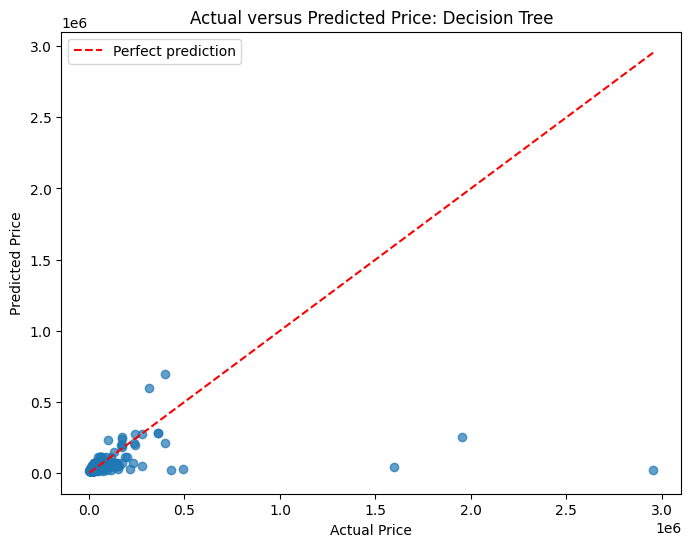

In [ ]:
best_model_name = car_results_df.loc[
    car_results_df["R2 Score"].idxmax(), "Model"
]

actual = y_test.values
predicted = car_predictions[best_model_name]

plt.figure(figsize=(8, 6))
plt.scatter(actual, predicted, alpha=0.7)

minimum = min(actual.min(), predicted.min())
maximum = max(actual.max(), predicted.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    color="red",
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title(f"Actual versus Predicted Price: {best_model_name}")
plt.legend()
plt.show()
